**Name :** ريتاج خالد الاشقر

**ID :** 446008786

**شعبة :** 1

## Introduction

In this lab, we will implement Feedforward Neural Network model for __sentence classification__ using Tensorflow and Keras. Given a sentence our model will predict if it is a positive or negative piece of texts. The dataset we are going to use the Stanford Sentiment Treebank dataset, which is one of the popular dataset in NLP field. It was eveloped as part of the Stanford NLP group's research, and consists of a collection of movie reviews from the Internet Movie Database (IMDb), annotated with fine-grained sentiment labels. It is structured to provide both sentence-level and phrase-level sentiment annotations.

Nevertheless, for this lab we'll  simplify the task, and we will work on part of the dataset using only the sentence-level, and translate the 5-way classification task (mulitclass probem) into 2-way classification task (Binary classification problem) (0 $\rightarrow$ _negative,_ ;1 $\rightarrow$ positive),,


All in all, __the main objectives__ of today lab are the following:
- Learn how to build percepton and Feedforward Neural Network Model in Keras
- Preprocessing of the input (e.g. one-hot-encoding)

## 1. Loading the data

Let's load the Stanford Sentiment Treebank. In our course folder, you will find a folder named __Stanford_data__, which contains the following CSV files: train, test, and dev.

You should create a folder called Data inside your Colab Notebooks folder. Then, download the __Stanford_data__ folder into it. Next, you will need to mount your Google Drive and provide access to the notebook. This will require one-step authentication. When you run the cell below, please follow the instructions carefully.

Once you have mounted everything,


make sure ```path = 'drive/My Drive/Colab Notebooks/''``` is the correct path for the data.

(For your reference, the data can be originaly downloaded from here: [the train/dev/test Stanford Sentiment Treebank distribution](http://nlp.stanford.edu/sentiment/trainDevTestTrees_PTB.zip).)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
#change this path to where you have saved the Data folder in your driver
path = '/content/drive/MyDrive/Colab Notebooks/Stanford_data'
#'/content/drive/My Drive/Colab Notebooks/data'
os.chdir(path)

In [ ]:
#Import numpy, pandas and tensorflow packages that we will use here.
import numpy as np
import pandas as pd
import tensorflow as tf

In [ ]:
# set seed for replicability of results
np.random.seed(1)
tf.random.set_seed(2)

In [ ]:
# Load the data as a datafram.
training_set = pd.read_csv('training.csv')
test_set = pd.read_csv('test.csv')
dev_set = pd.read_csv('dev.csv')

#Print the size of each set.
print(len(training_set))
print(len(test_set))
print(len(dev_set))

6920
1821
872


## 2. Examining the data

In [ ]:
# Print a sample of negative text chunks
print(training_set.loc[training_set['label']==0].sample(3))
print(test_set.loc[test_set['label']==0].sample(3))
print(dev_set.loc[dev_set['label']==0].sample(3))


      label                                               text
5874      0           And Diesel is n't the actor to save it .
5033      0  Director David Fincher and writer David Koepp ...
3908      0                    A fifty car pileup of cliches .
      label                                               text
1684      0  Fairly successful at faking some pretty cool s...
1255      0  For a shoot - 'em - up , Ballistic is oddly li...
1712      0  The only thing that could possibly make them l...
     label                                               text
537      0  Chokes on its own depiction of upper-crust dec...
733      0  What is 100 % missing here is a script of even...
671      0  It 's so mediocre , despite the dynamic duo on...


In [ ]:
# Print a sample of positive text chunks\
print(training_set.loc[training_set['label']==1].sample(3))
print(test_set.loc[test_set['label']==1].sample(3))
print(dev_set.loc[dev_set['label']==1].sample(3))


      label                                               text
2282      1  This is one of the outstanding thrillers of re...
2467      1  This often-hilarious farce manages to generate...
2222      1  That the real Antwone Fisher was able to overc...
     label                                               text
18       1  Scores a few points for doing what it does wit...
399      1  As if to prove a female director can make a mo...
752      1  A resonant tale of racism , revenge and retrib...
     label                                               text
511      1  We have n't seen such hilarity since Say It Is...
154      1  Having had the good sense to cast actors who a...
139      1  Has a lot of the virtues of Eastwood at his be...


## 3. Preprocessing the data
Once data is loaded the next step is to preprocess it to obtain the vectorized form (i.e. the process of transforming text into numeric tensors), which basically consist of:

- Tokenization, tipically segment the text into words. (Alternatively, we could segment text into characters, or extract n-grams of words or characters.)
- Definition of the dictionary index and vocabulary size (in this case we set to 1000 most frequent words)
- Transform each word into a vector.


There are multiple ways to vectorize tokens. The main two are the following: ___One-hot encoding___ and ___word embedding___. In this lab, we'll use Keras basic tools to obtain the one-hot encoding, and we'll leave word embeddings for the successive labs.

In [ ]:
from sklearn.utils import shuffle

# Shuffle dataset
training_set = shuffle(training_set)
dev_set = shuffle(dev_set)
test_set = shuffle(test_set)

# Obtain text and label vectors, and tokenize the text
train_texts = training_set.text
train_labels = training_set.label

dev_texts = dev_set.text
dev_labels = dev_set.label

test_texts = test_set.text
test_labels = test_set.label

In [ ]:
print(training_set.loc[0])
print(train_labels.loc[0])

label                                                    1
text     The Rock is destined to be the 21st Century 's...
Name: 0, dtype: object
1


### 3.1. One-hot encoding of the data

One-hot encoding is the most basic way to convert a token into a vectort. Here, we'll turn the input vectors into (0,1)-vectors. The process consist of associating a unique integer-index with every word in the vocabulary.

>>>>>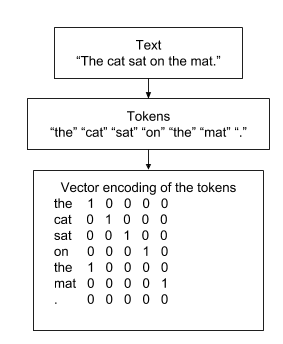


For example, if the tokenized vector contains a word that its dictionary index is 14, then in the processed vector, the 14th entry of the vector will be 1 and the rest will set to 0.

Note that when using keras built-in tools for indexing, ```0``` is a reserved index that won't be assigned to any word.

In [ ]:
from tensorflow.keras.preprocessing import text, sequence
from tensorflow.keras import utils

# Create a tokenize that takes the 1000 most common words
tokenizer = text.Tokenizer(num_words=1000)

# Build the word index (dictionary)
tokenizer.fit_on_texts(train_texts) # Create word index using only training part

# Vectorize texts into one-hot encoding representations
x_train = tokenizer.texts_to_matrix(train_texts, mode='binary')
x_dev = tokenizer.texts_to_matrix(dev_texts, mode='binary')
x_test = tokenizer.texts_to_matrix(test_texts, mode='binary')

# Converts the labels to a one-hot representation
y_train = train_labels
y_dev = dev_labels
y_test = test_labels

print('Text of the first examples: \n{}\n'.format(train_texts.iloc[0]))
print('Vector of the first example:\n{}\n'.format(x_train[0]))
print('Binary representation of the output:\n{}\n'.format(y_train[0]))

print('Shape of the training set (nb_examples, vector_size): {}\n'.format(x_train.shape))

Text of the first examples: 
A lame comedy .

Vector of the first example:
[0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 

In [ ]:
# Recover the word index that was created with the tokenizer
word_index = tokenizer.word_index
print('Found {} unique tokens.\n'.format(len(word_index)))
word_count = tokenizer.word_counts
print("Show the most frequent word index:")
for i, word in enumerate(sorted(word_count, key=word_count.get, reverse=True)):
    print('   {} ({}) --> {}'.format(word, word_count[word], word_index[word]))
    if i == 9:
        print('')
        break

for i, word in enumerate(sorted(word_count, key=word_count.get, reverse=False)):
    print('   {} ({}) --> {}'.format(word, word_count[word], word_index[word]))
    if i == 9:
        print('')
        break

Found 13839 unique tokens.

Show the most frequent word index:
   the (5996) --> 1
   a (4385) --> 2
   and (3869) --> 3
   of (3680) --> 4
   to (2464) --> 5
   is (2099) --> 6
   's (2025) --> 7
   it (1952) --> 8
   that (1613) --> 9
   in (1581) --> 10

   comforting (1) --> 7198
   tim (1) --> 7199
   mccann (1) --> 7200
   saigon (1) --> 7201
   simmering (1) --> 7202
   drowning (1) --> 7203
   plateau (1) --> 7204
   interrogation (1) --> 7205
   profession (1) --> 7206
   rancid (1) --> 7207



Check what we obtain when we vectorize words that are out of the index (_out of vocabulary_ words).

In [ ]:
oov_sample = ['saddam', 'plausible']
sequences = tokenizer.texts_to_matrix(oov_sample)
print(sequences[0])

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.

## 4. Building percepton model architecture using Keras
When we build a neural network we usually take into account the following points:
- The __layers__, and how they are combined (that is, the structure and parameters of the model)
- The __input__ and the __labeled output__ data that the model needs to map.
- The __activiation function__ of the layers

Keras provide a simple framework for combining layers. There are available two types of classes for building the model: The _Sequential_ Class and the _functional_ API.

The _functional_ API is designed for directed acyclic graph (DAG) structures, allowing you to create complex, non-linear models. In contrast, the _Sequential_ class is used for linear stacks of layers, making it the most common and simplest architecture.

As we are solvin binary clasasification problem, we will build a linear percepton (logistic regression) which is the most simple neural network model.

The logistic regression can be implemented in Keras using ```Dense``` layer. ```Dense``` implements the following  operation:

> ```output = activation(dot(input, kernel) + bias)```

where activation is the element-wise activation function passed as the ```activation``` argument (_sigmoid_ function in our case), ```kernel``` is a weights matrix created by the layer, and ```bias``` is a bias vector created by the layer.

Remenber from the slides that mathematically can be written as follows (where $W$ is the ```kernel```, and $X$ is the ```input```):
> $sigmoid(W^{T}X + b)$


Please note: Regarding input data, we will use the __one-hot encoding__ (see previous sections). We need to indicate the input shape for only the first hidden layer.



In [ ]:
# prompt: create a keras percepron train on training_set and test on test_set

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Create a sequential model
model = Sequential()

# Add a dense layer with sigmoid activation function
model.add(Dense(1, input_dim=x_train.shape[1], activation='sigmoid'))

# Compile the model
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# Train the model
model.fit(x_train, y_train, epochs=10, batch_size=32, validation_data=(x_dev, y_dev))

# Evaluate the model on the test set
loss, accuracy = model.evaluate(x_test, y_test)
print('Test accuracy:', accuracy)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5809 - loss: 0.6772 - val_accuracy: 0.6514 - val_loss: 0.6572
Epoch 2/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6795 - loss: 0.6427 - val_accuracy: 0.6995 - val_loss: 0.6289
Epoch 3/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7201 - loss: 0.6158 - val_accuracy: 0.7225 - val_loss: 0.6070
Epoch 4/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7370 - loss: 0.5939 - val_accuracy: 0.7282 - val_loss: 0.5896
Epoch 5/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7529 - loss: 0.5758 - val_accuracy: 0.7420 - val_loss: 0.5754
Epoch 6/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7663 - loss: 0.5604 - val_accuracy: 0.7374 - val_loss: 0.5637
Epoch 7/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7734 - loss: 0.5471 - val_accuracy: 0.7431 - val_loss: 0.5539
Epoch 8/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7777 - loss: 0.5355 - val_accuracy: 0.

****

**Exercise #1:
Answer the following questions:**
- How many layers has the model?
- What is the input size?
- How many parameters has the models? What is the relationship with the input size?

**Exercise 1 The Answers**


**1 :**

Only one layer

**2 :**

**The answer is in the code**

so the output was (6920, 1000) the 6920 is the samples

and the 1000 is the "Input size"


**3 :**


OK so the peramets are 1000 and with the bais 1 so its 1001 just as the code down there said the summery of the whole model is 1001 perametrs



In [ ]:
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │         1,001 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,005 (11.74 KB)

 Trainable params: 1,001 (3.91 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,004 (7.83 KB)

In [ ]:
print(x_train.shape)

(6920, 1000)


****

## 3. Building a single feedforward Neural Network model
Based on previous code we'll extend the model to single feedforward Neural network with one hidden units. For that we'll make use of a fully connected (```Dense```) layers with a ```relu``` activation. In this case the hidden layer will have 16 hidden units (feel free to explore different dimensionality of hidden units).

Remenber that applying ```Dense``` layer with ```relu``` activation we are implementing the following tensor operation:

```
output = relu(dot(W, input) + b)
```
**Exercise #2: Answer the following questions:**
- What does having 16 hidden units mean? What is the size of matrix ```W```?

-----

Increasing the number of hidden units we are allowing the network to learn more complex representations, but at the same time we are making the network more computationally expensive and may lead to overfit the training data.

Regarding the architecture, there are three main decisions that we need to take:
- The number of layers
- The number of hidden units for each layers
- Activation function of the layers




In [ ]:
#BUILING RETAJ'S MODLE the single feedforwerd neural network model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model2 = Sequential()

#the hidden lyer
model2.add(Dense(
    16,
    input_dim=x_train.shape[1],
    activation='relu'
))
# i added another layer and its 32
model2.add(Dense(
    32,
    input_dim=x_train.shape[1],
    activation='relu'
))

#output layer
model2.add(Dense(
    1,
    activation='sigmoid'
))


model2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 16)             │        16,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,593 (64.82 KB)

 Trainable params: 16,593 (64.82 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#did the compile just like the other code

model2.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
#and now do the fitting and the training

history2 = model2.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_data=(x_dev, y_dev)
)
#After that i evalute the code after the training

test_loss, test_accuracy = model2.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


Epoch 1/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.6374 - loss: 0.6424 - val_accuracy: 0.7294 - val_loss: 0.5459
Epoch 2/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7678 - loss: 0.4927 - val_accuracy: 0.7626 - val_loss: 0.5051
Epoch 3/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7981 - loss: 0.4333 - val_accuracy: 0.7615 - val_loss: 0.5165
Epoch 4/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8175 - loss: 0.3964 - val_accuracy: 0.7534 - val_loss: 0.5355
Epoch 5/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8418 - loss: 0.3566 - val_accuracy: 0.7534 - val_loss: 0.5663
Epoch 6/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8675 - loss: 0.3109 - val_accuracy: 0.7477 - val_loss: 0.6096
Epoch 7/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8918 - loss: 0.2644 - val_accuracy: 0.7408 - val_loss: 0.6694
Epoch 8/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9153 - loss: 0.2190 - val_accuracy: 0.

In [ ]:
model2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 16)             │        16,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,781 (194.46 KB)

 Trainable params: 16,593 (64.82 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 33,188 (129.64 KB)

**Anwsering Excierise 2**

Having **16 hidden units** means that the hidden layer has **16 neurons**, and each neuron receives all **1000 input features**.

The size of the weight matrix **W** is **1000 × 16**, which means it contains **16,000 weights**. In addition, there are **16 bias values**, one for each hidden unit, giving the hidden layer a total of **16,016 trainable parameters**.

Using the graph below as a reference, please build a neural network with a fully connected architecture that includes one hidden layer and an output layer to predict the sentiment of the input review.

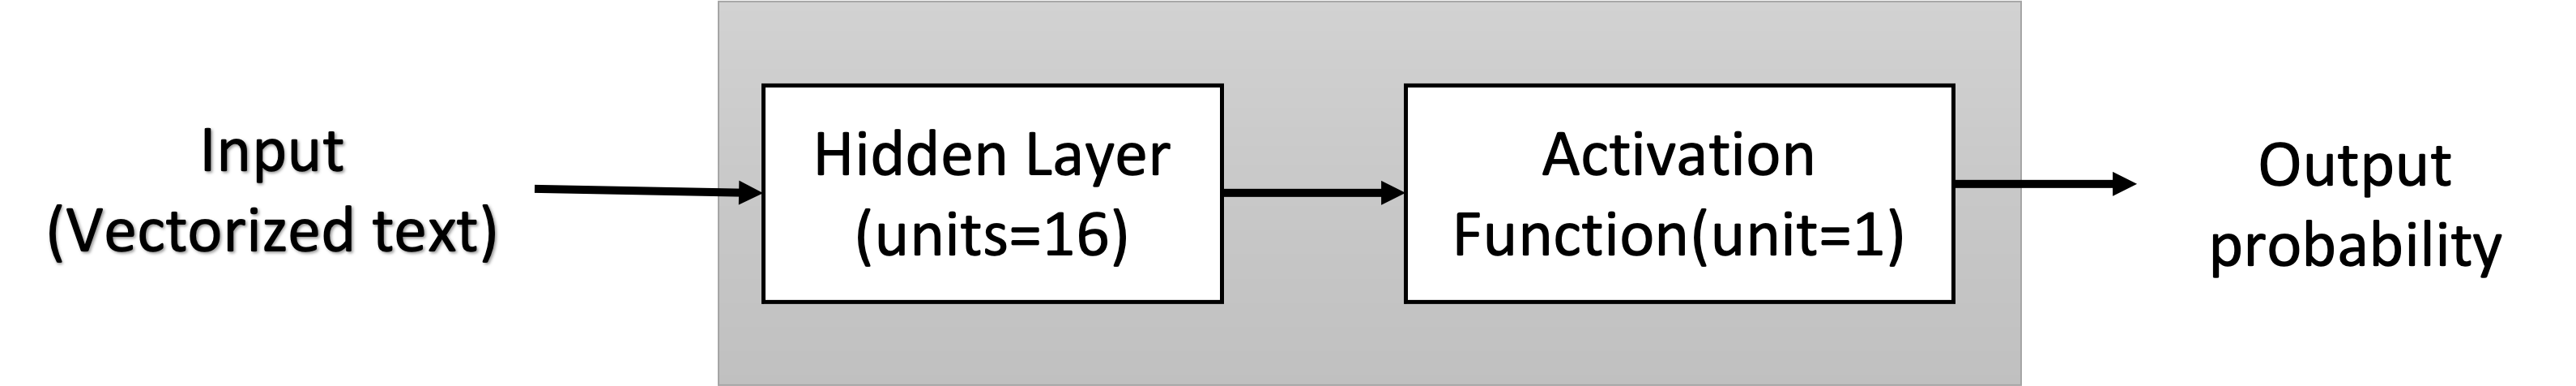


****


**Notes for me to remeber**

Training Set

     ↓

Model learns


Development Set

     ↓

We improve/check the model


Test Set

     ↓

Final evaluation

Training → Learn

Development/Validation → Check and improve

Test → Final evaluation

ok so why did we put the sigmont 1 and can we change it ? no because its binary and its the output